# Recovery completeness — the magnitude of 90% recovery

A one-sided band (detected in one survey, not the other) is judged against the missing survey's *limit*. Rather than a 5σ depth (a ~50% point),
we want the magnitude at which the survey recovers 90% of sources. On field 860: PS1's published injection-recovery per stack, and a model for
ZTF, which publishes none. The pipeline currently uses cross-match limits instead (`ff.completeness_limits`); see `plan_completeness.md`.

In [ ]:
import os, sys, glob, warnings; sys.path.insert(0, '..')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import norm
from astropy.io import fits
import astropy.units as u
from Extracting import ps1_stack
warnings.filterwarnings('ignore')
pd.set_option('display.width', 200)
FIELD, D = 860, '../Data'
MGRID = np.linspace(19, 24.5, 400)                                   # the magnitude grid every curve is evaluated on
def vline(ax, x, color, y, ls='--', label=None):
    if np.isfinite(x):
        ax.axvline(x, color=color, ls=ls, lw=1.2, label=label); ax.text(x, y, f'{x:.2f}', color=color, fontsize=8, rotation=90, ha='right', va='top')

## PS1: the published injection-recovery (`StackDetEffMeta`)

For every 3π deep stack (skycell × filter) PS1 injected 500 fake PSF sources in each of 13 magnitude bins at fixed offsets from `magref`
(−2 … +2 mag; `magref` = the stack's `detectionThreshold`, ≈ its 50% point) and counted how many psphot's peak detection found in that band's
stack (`counts01`–`counts13`). Forced photometry from other bands does not count. Flewelling et al. 2020, Table D29; Magnier et al. 2020.

One CasJobs query per field, keyed on the skycells the field's objects sit in (`merged.parquet`). Cached to the path below (the field 860 pull from 11/20).

In [ ]:
DETEFF = f'{D}/fields/{FIELD:06d}/review/experiments/ps1_stack_deteff_{FIELD}.parquet'
OFFSETS = [f'offset{i:02d}' for i in range(1, 14)]; COUNTS = [f'counts{i:02d}' for i in range(1, 14)]

def field_skycells(field):
    """The (projectionID, skyCellID) pairs the field's objects sit in, per band, from the builder's merged table."""
    cols = [f'{b}_ps1_{c}' for b in 'gri' for c in ('projcell', 'skycell')]
    m = pd.read_parquet(f'{D}/fields/{field:06d}/merged.parquet', columns=cols)
    cells = set()
    for b in 'gri':
        v = m[[f'{b}_ps1_projcell', f'{b}_ps1_skycell']].dropna(); v = v[v.iloc[:, 0] > 0]
        cells |= set(map(tuple, v.drop_duplicates().astype(int).values))
    return sorted(cells)

def fetch_stack_deteff(cells):
    """StackMeta ⋈ StackDetEffMeta for the deep gri stacks of these (projectionID, skyCellID): one row per stack."""
    from Source_Analysis.casjobs import MASTCASJOBS as J
    where = ' or '.join(f'(m.projectionID={p} and m.skyCellID={s})' for p, s in cells)
    offs = ', '.join(f'e.{o}, e.{c}' for o, c in zip(OFFSETS, COUNTS))
    return J.quick(f"""select m.projectionID, m.skyCellID, m.filterID, m.detectionThreshold, m.nP2Images, e.magref, e.nInjected, {offs}
                       from StackMeta m join StackDetEffMeta e on e.stackImageID = m.stackImageID
                       where m.stackTypeID = 1 and m.filterID <= 3 and ({where})""", task_name='deteff').to_pandas()

def recovery_mag(st, p):
    """Each stack's magnitude at recovered fraction p: linear interpolation between the first pair of offset bins that straddle p."""
    o = st[OFFSETS].values.astype(float); f = st[COUNTS].values / st.nInjected.values[:, None]
    out = np.full(len(st), np.nan)
    for k in range(len(st)):
        below = np.flatnonzero(f[k] < p)
        if len(below) and below[0] > 0:
            i = below[0]; out[k] = o[k, i - 1] + (f[k, i - 1] - p) / (f[k, i - 1] - f[k, i]) * (o[k, i] - o[k, i - 1])
    return st.magref.values + out

if os.path.exists(DETEFF):
    st = pd.read_parquet(DETEFF)
else:
    st = fetch_stack_deteff(field_skycells(FIELD)); os.makedirs(os.path.dirname(DETEFF), exist_ok=True); st.to_parquet(DETEFF)
st['band'] = st.filterID.astype(int).map({1: 'g', 2: 'r', 3: 'i'}); st['skyCellID'] = st.skyCellID.astype(int)
st['m50'], st['m90'] = recovery_mag(st, 0.5), recovery_mag(st, 0.9)
g = st.groupby('band')
pd.DataFrame({'stacks': g.size(), 'magref': g.magref.median(), 'm50': g.m50.median(), 'm90': g.m90.median(),
              'm90 p10': g.m90.quantile(0.1), 'm90 p90': g.m90.quantile(0.9), 'nP2Images': g.nP2Images.median()}).round(2).loc[list('gri')]

,stacks,magref,m50,m90,m90 p10,m90 p90,nP2Images
band,,,,,,,
g,420,22.80,22.85,22.37,21.99,22.55,19.0
r,420,22.38,22.43,21.96,21.63,22.30,20.0
i,420,22.52,22.54,22.14,21.83,22.32,37.0


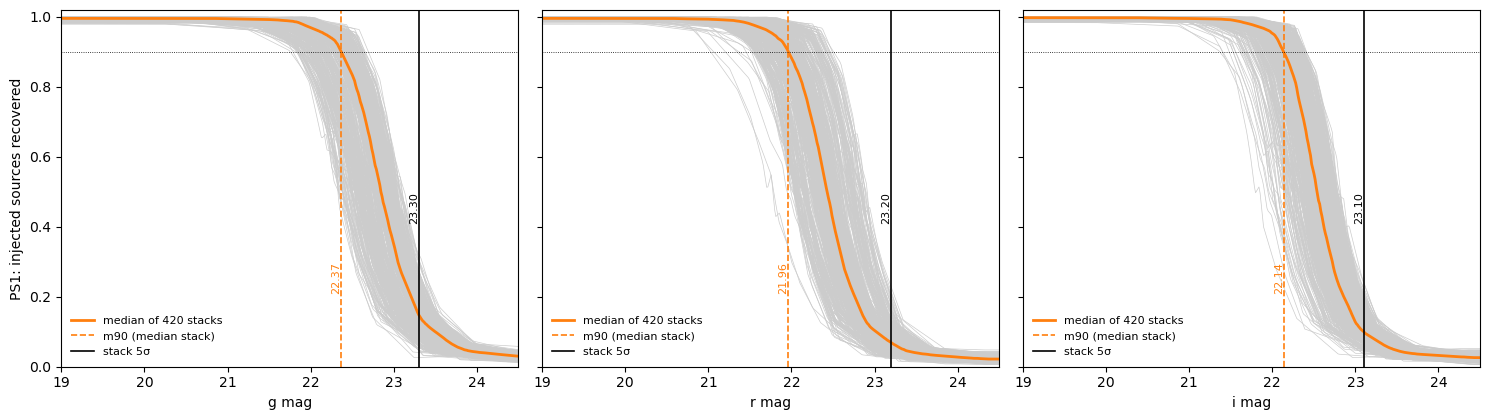

In [ ]:
# Every stack's recovery curve (grey), the field median (orange) and where it crosses 90%.
def ps1_curves(s):
    """Each stack's recovered fraction on MGRID (interpolated between its 13 bins; clamped to the end values outside them)."""
    mags = s.magref.values[:, None] + s[OFFSETS].values; frac = s[COUNTS].values / s.nInjected.values[:, None]
    return np.array([np.interp(MGRID, mags[k], frac[k]) for k in range(len(s))])
ps1_median = {}
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3), sharey=True)
for ax, b in zip(axes, 'gri'):
    s = st[st.band == b]; curves = ps1_curves(s); ps1_median[b] = np.median(curves, axis=0)
    for c in curves: ax.plot(MGRID, c, color='0.8', lw=0.5, zorder=0)
    ax.plot(MGRID, ps1_median[b], color='C1', lw=2, label=f'median of {len(s)} stacks')
    vline(ax, s.m90.median(), 'C1', 0.3, label='m90 (median stack)'); vline(ax, ps1_stack.STACK_5SIG[b], 'k', 0.5, ls='-', label='stack 5σ')
    ax.axhline(0.9, color='k', lw=0.6, ls=':'); ax.set_xlim(MGRID[0], MGRID[-1]); ax.set_ylim(0, 1.02)
    ax.set_xlabel(f'{b} mag'); ax.legend(frameon=False, fontsize=8, loc='lower left')
axes[0].set_ylabel('PS1: injected sources recovered')
plt.tight_layout(); plt.show()

### All-sky: every 3π deep stack

`Extracting.ps1_stack.fetch_stack_deteff` pulls the same join for every gri deep stack (599,311 rows, 21 chunked quick queries) into `Data/ps1/stack_deteff_gri.parquet`;
`ps1_stack.stack_recovery_mag` is what the filter reads per object. Below, every stack's recovery curve (its 13 bins, light grey) with the median and 10th/90th percentile curves per band: all stacks on top,
and without the stacks that never reach 90% (next cell) underneath. The faint-end floor of a few per cent is spurious matches to real sources.

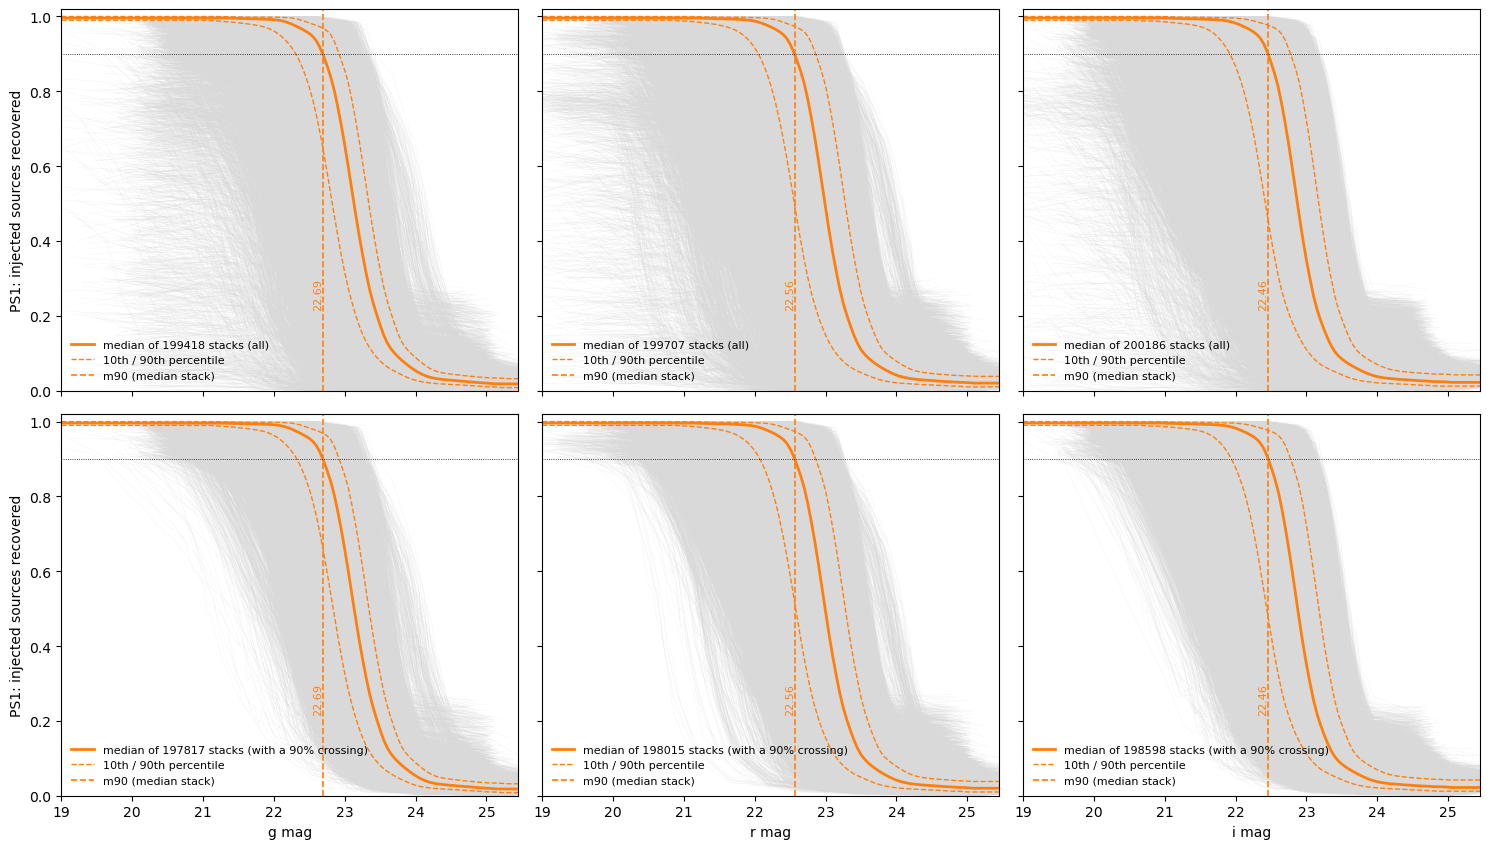

In [ ]:
from matplotlib.collections import LineCollection
MG = np.arange(19, 25.5, 0.05)                                       # coarser, wider grid for the all-sky curves (magref spans 20.5-24.2)
sky = ps1_stack.stack_deteff().copy()
sky['m50'], sky['m90'] = ps1_stack.recovery_mag(sky, 0.5), ps1_stack.recovery_mag(sky, 0.9)
nocross = ~np.isfinite(sky.m90)                                      # below 90% already in the brightest bin: no crossing to interpolate

def curves_on(s, grid):
    mags = s.magref.values[:, None] + s[OFFSETS].values; frac = s[COUNTS].values / s.nInjected.values[:, None]
    return np.array([np.interp(grid, mags[k], frac[k]) for k in range(len(s))], dtype=np.float32)

sky_median = {}
fig, axes = plt.subplots(2, 3, figsize=(15, 8.6), sharex=True, sharey=True)
for row, keep, what in ((0, np.ones(len(sky), bool), 'all'), (1, ~nocross.values, 'with a 90% crossing')):
    for ax, b in zip(axes[row], 'gri'):
        s = sky[(sky.band == b).values & keep]; c = curves_on(s, MG)
        segs = np.stack([s.magref.values[:, None] + s[OFFSETS].values, s[COUNTS].values / s.nInjected.values[:, None]], axis=-1)
        ax.add_collection(LineCollection(segs, colors='0.85', linewidths=0.3, alpha=0.3, rasterized=True, zorder=0))
        lo, med, hi = np.percentile(c, [10, 50, 90], axis=0)
        if row == 0: sky_median[b] = med
        ax.plot(MG, med, color='C1', lw=2, label=f'median of {len(s)} stacks ({what})')
        ax.plot(MG, lo, color='C1', lw=1, ls='--', label='10th / 90th percentile'); ax.plot(MG, hi, color='C1', lw=1, ls='--')
        vline(ax, s.m90.median(), 'C1', 0.3, label='m90 (median stack)'); ax.axhline(0.9, color='k', lw=0.6, ls=':')
        ax.set_xlim(MG[0], MG[-1]); ax.set_ylim(0, 1.02); ax.legend(frameon=False, fontsize=8, loc='lower left')
for ax, b in zip(axes[1], 'gri'): ax.set_xlabel(f'{b} mag')
for ax in axes[:, 0]: ax.set_ylabel('PS1: injected sources recovered')
plt.tight_layout(); plt.show()

### Stacks that never reach 90%

`recovery_mag` returns NaN when the recovered fraction is already below $p$ in the brightest bin (magref − 2); for $p = 0.9$ that is 4,881 stacks (0.8%).
They are the stacks built from a handful of input exposures, so the skycell is only partly exposed: fakes dropped on the unexposed part are never found and the
curve plateaus at the covered fraction rather than at 1. Two examples below, against the median stack of the band, then the ZTF quadrants (main grid) that
contain one, drawn with `ztffields`: the southernmost ring of projection cells (the survey's edge at dec −30), the Galactic bulge, and a few cells at the pole.
`StackMeta.crval1/2` is the projection cell's tangent point, so skycell centres come from the tessellation (`ps1_skycells`).

,stacks,no 90% crossing,median recovery at magref-2
nP2 bin,,,
<5,2412,0.896,0.644
5-9,3476,0.379,0.934
10-19,186398,0.004,0.996
≥20,407025,0.002,0.996


4881 stacks without a 90% crossing; 4133 of them in the southernmost projection-cell ring (dec -32 to -28); 3720 still cross 50% (median m50 21.60 vs 23.01 for the rest)


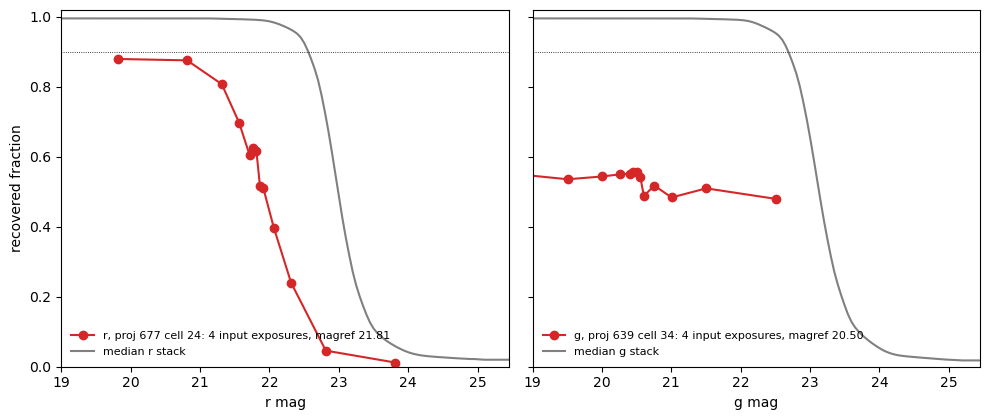

In [ ]:
sky['nP2 bin'] = pd.cut(sky.nP2Images, [0, 5, 10, 20, np.inf], right=False, labels=['<5', '5-9', '10-19', '≥20'])
g = sky.groupby('nP2 bin', observed=True)
display(pd.DataFrame({'stacks': g.size(), 'no 90% crossing': g.apply(lambda s: nocross[s.index].mean()).round(3),
                      'median recovery at magref-2': g.apply(lambda s: (s[COUNTS[0]] / s.nInjected).median()).round(3)}))
print(f'{nocross.sum()} stacks without a 90% crossing; {(nocross & (sky.crval2 == -30)).sum()} of them in the southernmost projection-cell ring (dec -32 to -28); '
      f'{np.isfinite(sky.m50[nocross]).sum()} still cross 50% (median m50 {sky.m50[nocross].median():.2f} vs {sky.m50[~nocross].median():.2f} for the rest)')

ex = [sky[nocross & (sky.band == 'r') & (sky.nP2Images == 4)].iloc[0],                   # a scaled-down curve: partial coverage
      sky[nocross & (sky[COUNTS[-1]] > 0.5 * sky[COUNTS[0]])].iloc[0]]                    # a flat one: the cell is mostly empty
fig, axes = plt.subplots(1, 2, figsize=(10, 4.3), sharey=True)
for ax, r in zip(axes, ex):
    mags, frac = r.magref + r[OFFSETS].values.astype(float), r[COUNTS].values / r.nInjected
    ax.plot(mags, frac, 'o-', color='C3', label=f'{r.band}, proj {r.projectionID} cell {r.skyCellID}: {r.nP2Images} input exposures, magref {r.magref:.2f}')
    ax.plot(MG, sky_median[r.band], color='0.5', lw=1.5, label=f'median {r.band} stack'); ax.axhline(0.9, color='k', lw=0.6, ls=':')
    ax.set_xlim(MG[0], MG[-1]); ax.set_ylim(0, 1.02); ax.set_xlabel(f'{r.band} mag'); ax.legend(frameon=False, fontsize=8, loc='lower left')
axes[0].set_ylabel('recovered fraction')
plt.tight_layout(); plt.show()

946 quadrants in 71 main-grid fields hold a stack with no 90% crossing


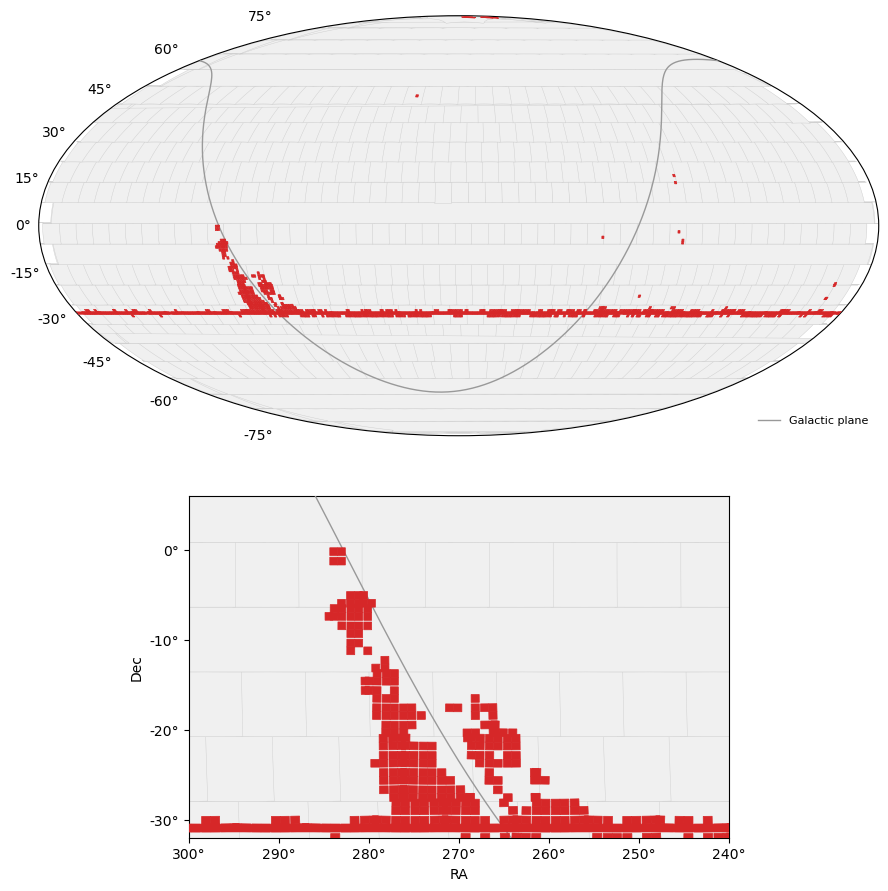

<Figure size 700x400 with 0 Axes>

<Figure size 700x400 with 0 Axes>

In [ ]:
import ztffields
from ztffields.plotting import FieldFigure
from astropy.coordinates import Galactic, ICRS
from Extracting import ps1_skycells as sc

def skycell_centres(proj, cell):
    """(ra, dec) of each skycell's centre: the middle of its non-overlapping core, through the projection cell's TAN WCS."""
    proj, cell = np.asarray(proj, int), np.asarray(cell, int)
    ra, dec = np.full(len(proj), np.nan), np.full(len(proj), np.nan)
    for p in np.unique(proj):
        sel = proj == p; r = sc.GRID[(sc.GRID[:, sc.PROJCELL] <= p).nonzero()[0][-1]]
        iy, ix = np.divmod(cell[sel], 10)
        x = 1 + sc.OVERLAP_PX + (ix + 0.5) * (r[sc.XCELL] - 2 * sc.OVERLAP_PX); y = 1 + sc.OVERLAP_PX + (iy + 0.5) * (r[sc.YCELL] - 2 * sc.OVERLAP_PX)
        ra[sel], dec[sel] = sc.cell_wcs(int(p)).all_pix2world(x, y, 1)
    return ra, dec

def to_plot(ra, dec):
    """ztffields' frame: astro icrs with origin 180 (east left), in radians."""
    return np.radians((180 - np.asarray(ra) + 180) % 360 - 180), np.radians(dec)

nc = sky[nocross].copy(); nc['ra'], nc['dec'] = skycell_centres(nc.projectionID, nc.skyCellID)
q = ztffields.radec_to_fieldid(nc[['ra', 'dec']].values, level='quadrant')
quads = list(map(tuple, q[q.fieldid < 1000].drop_duplicates().values))         # (fieldid, rcid) on the main grid
print(f'{len(quads)} quadrants in {q[q.fieldid < 1000].fieldid.nunique()} main-grid fields hold a stack with no 90% crossing')

gal = Galactic(l=np.linspace(0, 360, 721) * u.deg, b=np.zeros(721) * u.deg).transform_to(ICRS())
fig = plt.figure(figsize=(10, 9))
ff, fields = FieldFigure.from_level('quadrant'), FieldFigure.from_level('focalplane')
main = [f for f in fields.geodf.index if f < 1000]
ax = fig.add_axes([0.08, 0.5, 0.84, 0.48], projection='mollweide'); ax2 = fig.add_axes([0.08, 0.06, 0.84, 0.38])
for a in (ax, ax2):
    ff._figure = fields._figure = fig; ff._is_cartopy = fields._is_cartopy = False
    fields.plot_sky(fieldid=main, ax=a, facecolor='0.94', edgecolor='0.8', lw=0.3, colorbar=None, zorder=2)
    ff.plot_sky(fieldid=quads, ax=a, facecolor='C3', edgecolor='C3', lw=0.5, colorbar=None, zorder=4)
    gx, gy = to_plot(gal.ra.deg, gal.dec.deg); o = np.argsort(gx); a.plot(gx[o], gy[o], color='0.6', lw=1, zorder=3, label='Galactic plane')
ax.set_xticklabels([f'{int((180 - np.degrees(t)) % 360)}°' for t in ax.get_xticks()], fontsize=8); ax.grid(False); ax.legend(loc='lower right', fontsize=8, frameon=False)
ra0, ra1, d0, d1 = 240, 300, -32, 6                                   # zoom on the bulge cluster
ax2.set_xlim(np.radians(180 - ra1), np.radians(180 - ra0)); ax2.set_ylim(np.radians(d0), np.radians(d1)); ax2.set_aspect('equal')
xt, yt = np.arange(ra0, ra1 + 1, 10), np.arange(-30, d1, 10)
ax2.set_xticks(np.radians(180 - xt)); ax2.set_xticklabels([f'{v}°' for v in xt]); ax2.set_yticks(np.radians(yt)); ax2.set_yticklabels([f'{v}°' for v in yt])
ax2.set_xlabel('RA'); ax2.set_ylabel('Dec')
plt.show()

### Why: survey edge and crowding

Exposures per stack against declination (1° bins of the skycell centre), with the no-crossing fraction. Coverage drops from the usual ~20 to a few
exposures below dec −30 (the 3π limit; the southernmost projection cells reach −32) and only there. The Galactic-plane stacks have normal exposure
counts; their fakes are lost to crowding instead, so their curves plateau at the fraction of the cell psphot can still resolve rather than at 1.

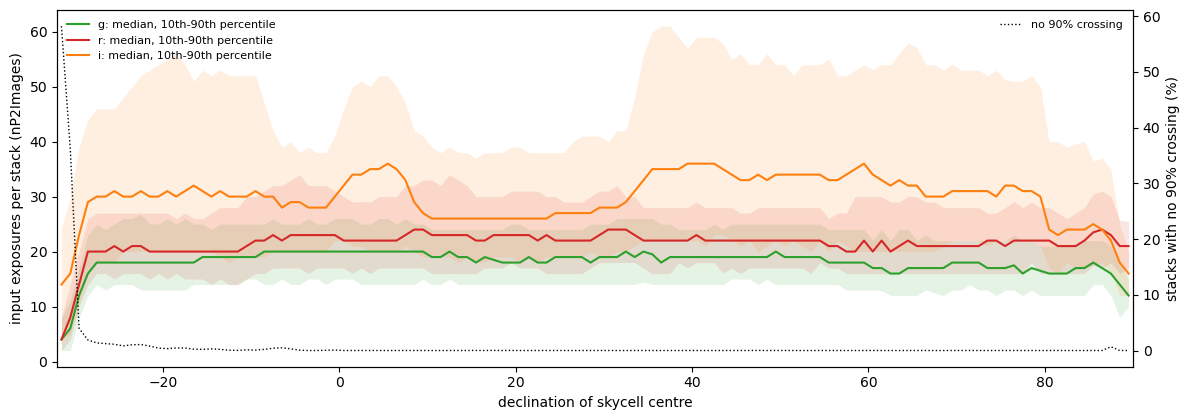

In [ ]:
sky['ra'], sky['dec'] = skycell_centres(sky.projectionID, sky.skyCellID)
sky['dec bin'] = pd.cut(sky.dec, np.arange(-32, 91, 1.0))
fig, ax = plt.subplots(figsize=(12, 4.3))
for b, c in zip('gri', ('C2', 'C3', 'C1')):
    g = sky[sky.band == b].groupby('dec bin', observed=True); x = np.array([i.mid for i in g.size().index])
    ax.plot(x, g.nP2Images.median(), color=c, lw=1.5, label=f'{b}: median, 10th-90th percentile')
    ax.fill_between(x, g.nP2Images.quantile(0.1), g.nP2Images.quantile(0.9), color=c, alpha=0.12, lw=0)
g = sky.groupby('dec bin', observed=True); x = np.array([i.mid for i in g.size().index])
ax2 = ax.twinx(); ax2.plot(x, 100 * g.apply(lambda s: nocross[s.index].mean()), color='k', lw=1, ls=':', label='no 90% crossing'); ax2.set_ylabel('stacks with no 90% crossing (%)')
ax.set_xlabel('declination of skycell centre'); ax.set_ylabel('input exposures per stack (nP2Images)'); ax.set_xlim(-32, 90)
ax.legend(frameon=False, fontsize=8, loc='upper left'); ax2.legend(frameon=False, fontsize=8, loc='upper right')
plt.tight_layout(); plt.show()

Three r stacks: a typical one, one on the survey edge and one in the bulge. Left, a 5′ cutout of the stack with the usual stretch; middle, the stack's
exposure-count map (`stk.r.unconv.num`); right, a 1′ zoom of the stack. The cutouts come from `fitscut.cgi` (six, 6 MB each) and are not kept.

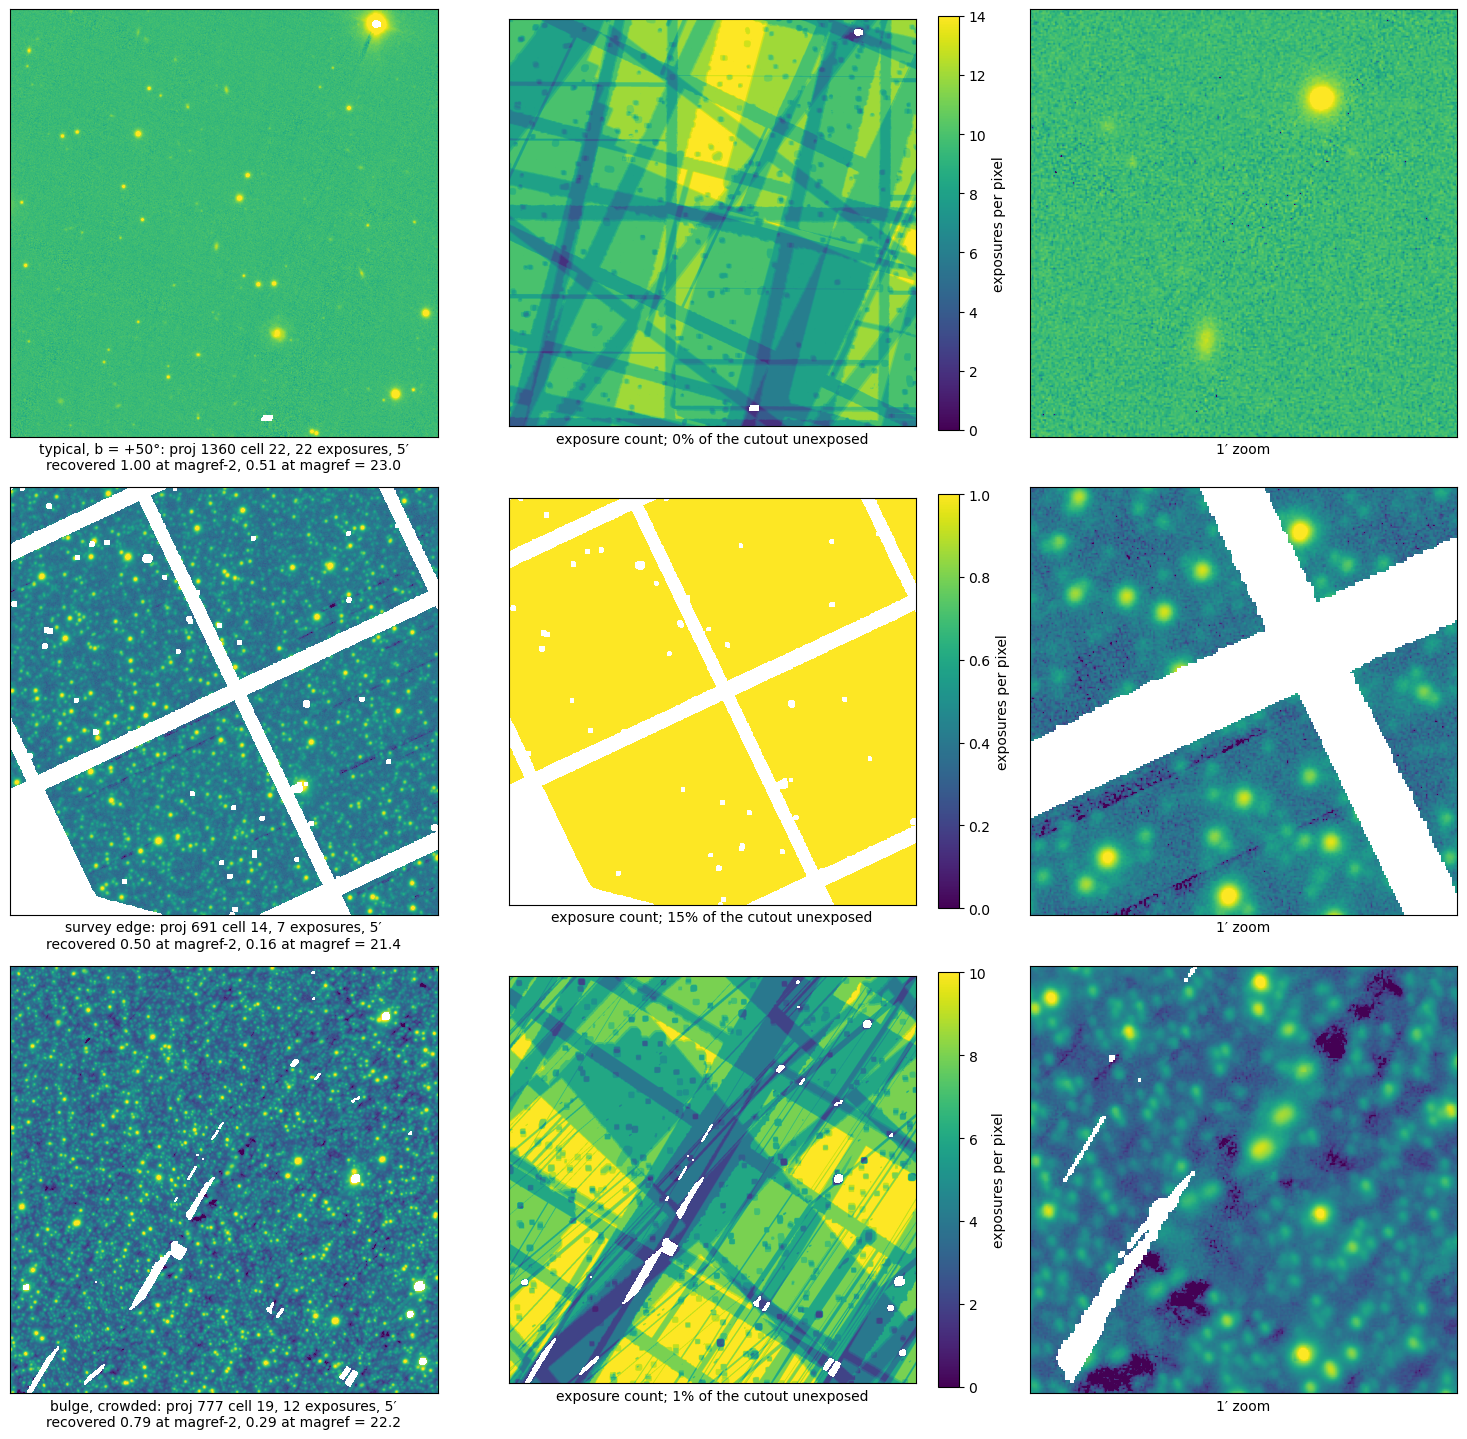

In [ ]:
import io, urllib.request
from astropy.visualization import simple_norm
from source_db.cutouts.render import DEFAULT_PERCENT, DEFAULT_STRETCH, PS1_FITSCUT, ps1_linear_flux
EXAMPLES = {'typical, b = +50°': (1360, 22), 'survey edge': (691, 14), 'bulge, crowded': (777, 19)}
SIZE, ZOOM = 1200, 240                                               # 0.25"/px: 5' cutout, 1' zoom

def stack_cutout(proj, cell, ra, dec, kind='', size=SIZE):
    """A fitscut FITS cutout of the r deep stack ('' = image, '.num' = exposures per pixel), fetched into memory."""
    fn = f'/rings.v3.skycell/{proj:04d}/{cell:03d}/rings.v3.skycell.{proj:04d}.{cell:03d}.stk.r.unconv{kind}.fits'
    with urllib.request.urlopen(f'{PS1_FITSCUT}?ra={ra:.5f}&dec={dec:.5f}&size={size}&format=fits&red={fn}', timeout=120) as u_:
        h = fits.open(io.BytesIO(u_.read()))[0]
    d = h.data.astype(np.float32)
    return d if kind else ps1_linear_flux(d, h.header)

fig, axes = plt.subplots(3, 3, figsize=(15, 14.5))
for row, (label, (proj, cell)) in zip(axes, EXAMPLES.items()):
    r = sky[(sky.band == 'r') & (sky.projectionID == proj) & (sky.skyCellID == cell)].iloc[0]
    img, num = stack_cutout(proj, cell, r.ra, r.dec), stack_cutout(proj, cell, r.ra, r.dec, '.num')
    norm = simple_norm(np.nan_to_num(img), DEFAULT_STRETCH, percent=DEFAULT_PERCENT)
    row[0].imshow(img, origin='lower', cmap='viridis', norm=norm)
    im = row[1].imshow(num, origin='lower', cmap='viridis', vmin=0); plt.colorbar(im, ax=row[1], fraction=0.046, label='exposures per pixel')
    c = SIZE // 2; row[2].imshow(img[c - ZOOM // 2: c + ZOOM // 2, c - ZOOM // 2: c + ZOOM // 2], origin='lower', cmap='viridis', norm=norm)
    f = r[COUNTS].values / r.nInjected
    row[0].set_xlabel(f'{label}: proj {proj} cell {cell}, {r.nP2Images} exposures, {SIZE / 240:.0f}′\nrecovered {f[0]:.2f} at magref-2, {f[6]:.2f} at magref = {r.magref:.1f}')
    row[1].set_xlabel(f'exposure count; {np.isnan(num).mean():.0%} of the cutout unexposed'); row[2].set_xlabel(f'{ZOOM / 240:.0f}′ zoom')
    for a in row: a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()

### PS1 coverage per ZTF field

The filter treats a band as uncovered by PS1 where its skycell has no deep stack or the stack never reaches 90% (`{b}_ps1_rec90_limit` NaN,
`ps1_checks` "stack reaches 90% at the position"). Per main-grid ZTF field and band, the fraction of the skycells inside it that are covered,
for the fields where any is not: a planning view of where PS1 cannot stand in before a field is filtered.

69 of 683 main-grid fields north of -30 have an uncovered band-skycell; 9 are under 90% covered in some band


band,g,r,i
fieldid,,,
234,0.798,0.367,0.330
233,0.696,0.580,0.429
282,0.924,0.637,0.462
283,0.997,0.884,0.730
213,0.816,0.895,0.965
232,1.000,0.917,0.404
384,1.000,0.933,0.785
281,0.997,0.938,0.552
333,1.000,0.945,0.672


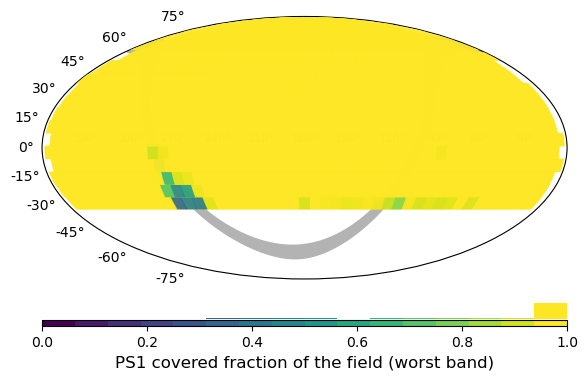

In [ ]:
full = pd.MultiIndex.from_product([[1, 2, 3], np.arange(*ps1_stack.DETEFF_PROJCELLS), np.arange(100)], names=['filterID', 'projectionID', 'skyCellID']).to_frame(index=False)
cov = full.merge(sky[['filterID', 'projectionID', 'skyCellID', 'm90']], how='left')          # every band-skycell of the grid, NaN m90 = no stack
cov['covered'] = np.isfinite(cov.m90); cov['band'] = cov.filterID.map(ps1_stack.FILTER_BAND)
cov['ra'], cov['dec'] = skycell_centres(cov.projectionID, cov.skyCellID)
cov = cov[cov.dec > -30].reset_index(drop=True)                                              # south of the DR2 cut the catalog check already drops the position
f = ztffields.radec_to_fieldid(cov[['ra', 'dec']].values, level='focalplane')
f = f[f < 1000].rename('fieldid').reset_index().merge(cov[['band', 'covered']], left_on='index_radec', right_index=True)
field_cov = f.pivot_table(index='fieldid', columns='band', values='covered', aggfunc='mean')[list('gri')]
incomplete = field_cov[(field_cov < 1).any(axis=1)]
print(f'{len(incomplete)} of {len(field_cov)} main-grid fields north of -30 have an uncovered band-skycell; {(field_cov < 0.9).any(axis=1).sum()} are under 90% covered in some band')
display(incomplete.sort_values('r').head(15).round(3))
fig = ztffields.skyplot_fields(field_cov.min(axis=1), figsize=(10, 5.5), projection='mollweide', colorbar='hist', cmap='viridis', vmin=0, vmax=1,
                               facealpha=0.9, edgecolor='None', label='PS1 covered fraction of the field (worst band)')
ax = next(a for a in fig.axes if a.name == 'mollweide'); ax.set_xticklabels([f'{int((180 - np.degrees(t)) % 360)}°' for t in ax.get_xticks()], fontsize=8); ax.grid(False)
plt.show()

## ZTF: a model of the detection probability

ZTF publishes no injection-recovery for its reference catalogs, so we model the recovery curve from the catalog's own threshold and noise.

**Setup, in flux.** In one quadrant and band, a point source of true PSF flux $f$ (DN) is measured as

$$\hat f = f + e, \qquad e \sim N(0,\,\sigma_f^2), \tag{1}$$

where $\sigma_f$ is the real scatter of the fitted flux. The catalog (`refpsfcat`) lists $\hat f$, an error $s$ and $\mathrm{S/N} = \hat f / s$.
For faint, background-limited sources $s$ is nearly the same for every source, $s \approx \bar s$. We call a source detected when
$\mathrm{S/N} \ge t$ with $t = 5$ (the catalog's own cut is 3), i.e. when

$$\hat f \ge t\,\bar s \equiv f_t. \tag{2}$$

**η: the pipeline's noise is underestimated.** $s$ is propagated from the pipeline's uncertainty image, a noise model (photon + read noise,
independent pixels) whose median is `MEDPUNC`. The scatter actually measured on blank sky, `GPCTSIG`, is 1.3–1.9 × larger in field 860: the model
omits correlated noise from resampling, flat-field and sky residuals, and faint-source confusion. We account for this with one factor per quadrant,

$$\eta \equiv \frac{\texttt{GPCTSIG}}{\texttt{MEDPUNC}}, \qquad \sigma_f = \eta\,\bar s, \tag{3}$$

the same error-rescaling factor deep-field catalogs measure with empty apertures. It matters here because the threshold (2) is set in the
pipeline's *modelled* noise, while whether a source crosses it is decided by the *real* scatter (1). Setting η = 1 asserts the pipeline's errors are
right.

**Detection probability, in flux.** From (1)–(3), with $\bar s = f_t / t$,

$$P(f) = P(\hat f \ge f_t) = \Phi\!\left(\frac{f - f_t}{\eta\,\bar s}\right) = \Phi\!\left[\frac{t}{\eta}\left(\frac{f}{f_t} - 1\right)\right]. \tag{4}$$

A source at the threshold flux is detected half the time whatever η is; η only widens the transition. The 90% point ($\Phi(1.2816) = 0.9$) is

$$\frac{f_{90}}{f_t} = 1 + \frac{1.2816\,\eta}{t}. \tag{5}$$

**In magnitudes.** With $m = \mathrm{ZP} - 2.5\log_{10} f$ and $m_t$ the magnitude of $f_t$, $f/f_t = 10^{-0.4(m - m_t)}$, so

$$P(m) = \Phi\!\left[\frac{t}{\eta}\left(10^{-0.4\,(m - m_t)} - 1\right)\right], \qquad
m_{90} = m_t - 2.5\log_{10}\!\left(1 + \frac{1.2816\,\eta}{t}\right). \tag{6}$$

**$m_t$ from the catalog.** Catalog magnitudes come from the same $\hat f$ as S/N, so the median magnitude of sources with 4.5 ≤ S/N ≤ 5.5 is the
magnitude of the measured flux $5\bar s$: that is $m_5$, with no bias correction, because $f_t$ is defined in measured flux.
Example (r, ccd 3, q 2): $m_5 = 23.35$, η = 1.74 → $m_{90} = 23.35 - 0.40 = 22.95$; with η = 1 the offset would be 0.25 mag.

**Not in the model.** The spread of $s$ within a quadrant (±25%), which broadens the curve; the bright-end plateau from blends, masks, failed fits
and the 1″ match; the fact that η is a pixel ratio where a flux ratio is wanted (measurable from the ZTF − PS1 scatter over $s$); extended sources.

In [ ]:
T = 5                                                                # our detection threshold in catalog S/N
def p_detect(m, m5, eta, t=T):
    """Eq. 6: probability that a point source of magnitude m has measured S/N >= t, from the quadrant's m5 and eta."""
    return norm.cdf((t / eta) * (10 ** (-0.4 * (m - m5)) - 1))
def m90(m5, eta, t=T):
    return m5 - 2.5 * np.log10(1 + 1.2816 * eta / t)

zq = []                                                              # per quadrant and band, from the local refpsfcat / refimg files
for f in sorted(glob.glob(f'{D}/ztf_data/field{FIELD:06d}/*_refpsfcat.fits')):
    p = os.path.basename(f).split('_'); b, ccd, qid = p[2][1], int(p[3][1:]), int(p[4][1:])
    h = fits.getheader(f.replace('refpsfcat', 'refimg')); d = fits.getdata(f, 1)
    m, snr = d['mag'] + h['MAGZP'], d['snr']                        # refpsfcat magnitudes are instrumental
    m5, eta = np.median(m[(snr >= 4.5) & (snr <= 5.5)]), h['GPCTSIG'] / h['MEDPUNC']
    zq.append({'band': b, 'ccd': ccd, 'qid': qid, 'maglim': h['MAGLIM'], 'm5': m5, 'eta': eta, 'm90': m90(m5, eta), 'm90_eta1': m90(m5, 1.0)})
zq = pd.DataFrame(zq)
zq.groupby('band')[['maglim', 'm5', 'eta', 'm90', 'm90_eta1']].median().round(2).loc[list('gri')]

,maglim,m5,eta,m90,m90_eta1
band,,,,,
g,23.71,23.350000,1.89,22.91,23.10
r,23.64,23.309999,1.85,22.89,23.06
i,23.03,22.700001,1.26,22.40,22.45


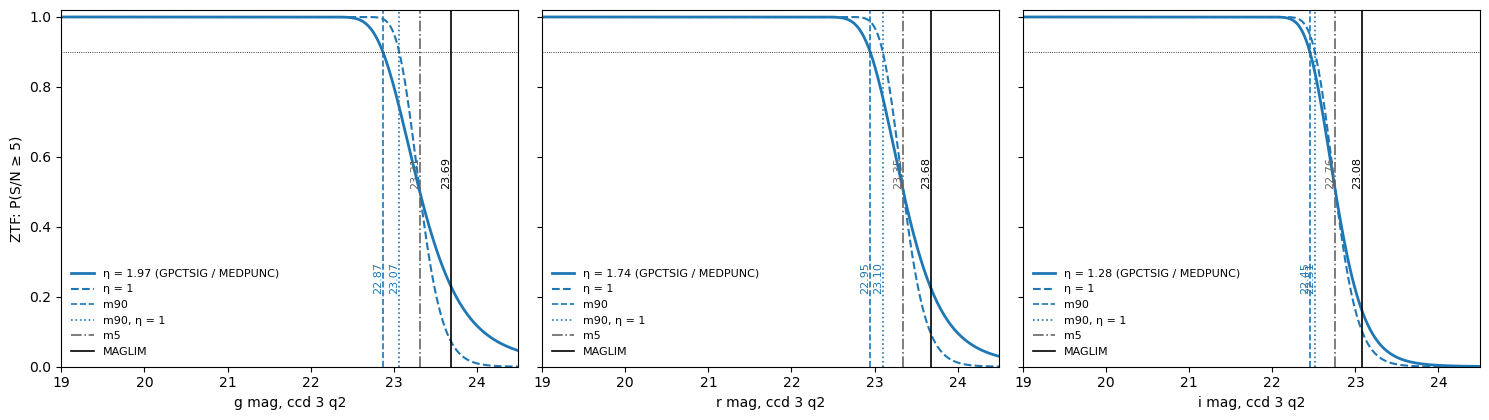

In [ ]:
# One quadrant: the model with its measured eta, and with eta = 1 (the pipeline's errors taken at face value).
QUAD = (3, 2)                                                        # (ccd, qid)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3), sharey=True)
for ax, b in zip(axes, 'gri'):
    q = zq[(zq.band == b) & (zq.ccd == QUAD[0]) & (zq.qid == QUAD[1])].iloc[0]
    ax.plot(MGRID, p_detect(MGRID, q.m5, q.eta), color='C0', lw=2, label=f'η = {q.eta:.2f} (GPCTSIG / MEDPUNC)')
    ax.plot(MGRID, p_detect(MGRID, q.m5, 1.0), color='C0', lw=1.5, ls='--', label='η = 1')
    vline(ax, q.m90, 'C0', 0.3, label='m90'); vline(ax, q.m90_eta1, 'C0', 0.3, ls=':', label='m90, η = 1')
    vline(ax, q.m5, '0.4', 0.6, ls='-.', label='m5'); vline(ax, q.maglim, 'k', 0.6, ls='-', label='MAGLIM')
    ax.axhline(0.9, color='k', lw=0.6, ls=':'); ax.set_xlim(MGRID[0], MGRID[-1]); ax.set_ylim(0, 1.02)
    ax.set_xlabel(f'{b} mag, ccd {QUAD[0]} q{QUAD[1]}'); ax.legend(frameon=False, fontsize=8, loc='lower left')
axes[0].set_ylabel('ZTF: P(S/N ≥ 5)')
plt.tight_layout(); plt.show()

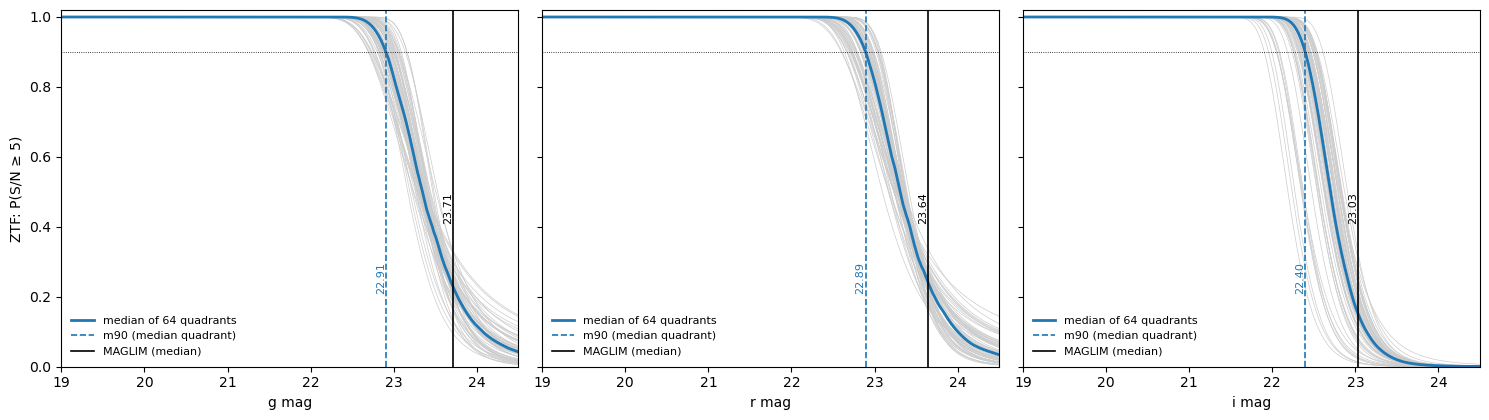

In [ ]:
# Every quadrant's model curve (grey), the field median (blue) and where it crosses 90%.
ztf_median = {}
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3), sharey=True)
for ax, b in zip(axes, 'gri'):
    s = zq[zq.band == b]; curves = np.array([p_detect(MGRID, r.m5, r.eta) for r in s.itertuples()]); ztf_median[b] = np.median(curves, axis=0)
    for c in curves: ax.plot(MGRID, c, color='0.8', lw=0.5, zorder=0)
    ax.plot(MGRID, ztf_median[b], color='C0', lw=2, label=f'median of {len(s)} quadrants')
    vline(ax, s.m90.median(), 'C0', 0.3, label='m90 (median quadrant)'); vline(ax, s.maglim.median(), 'k', 0.5, ls='-', label='MAGLIM (median)')
    ax.axhline(0.9, color='k', lw=0.6, ls=':'); ax.set_xlim(MGRID[0], MGRID[-1]); ax.set_ylim(0, 1.02)
    ax.set_xlabel(f'{b} mag'); ax.legend(frameon=False, fontsize=8, loc='lower left')
axes[0].set_ylabel('ZTF: P(S/N ≥ 5)')
plt.tight_layout(); plt.show()

### Using the header MAGLIM as the threshold magnitude

ZTF documents MAGLIM as the median catalog magnitude at 4.5 ≤ S/N ≤ 5.5 (Masci et al. 2019), i.e. $m_5$. The reference-image pipeline
actually takes the median over 3.0 ≤ S/N ≤ 5.5 (its log), which lands 0.33–0.37 mag fainter than $m_5$ in every quadrant of field 860. Below,
the model with MAGLIM in place of $m_5$ (dashed) against the catalog $m_5$ (solid), same η.

,m5,maglim,m90 (catalog m5),m90 (MAGLIM as m5)
band,,,,
g,23.350000,23.71,22.91,23.28
r,23.309999,23.64,22.89,23.22
i,22.700001,23.03,22.40,22.72


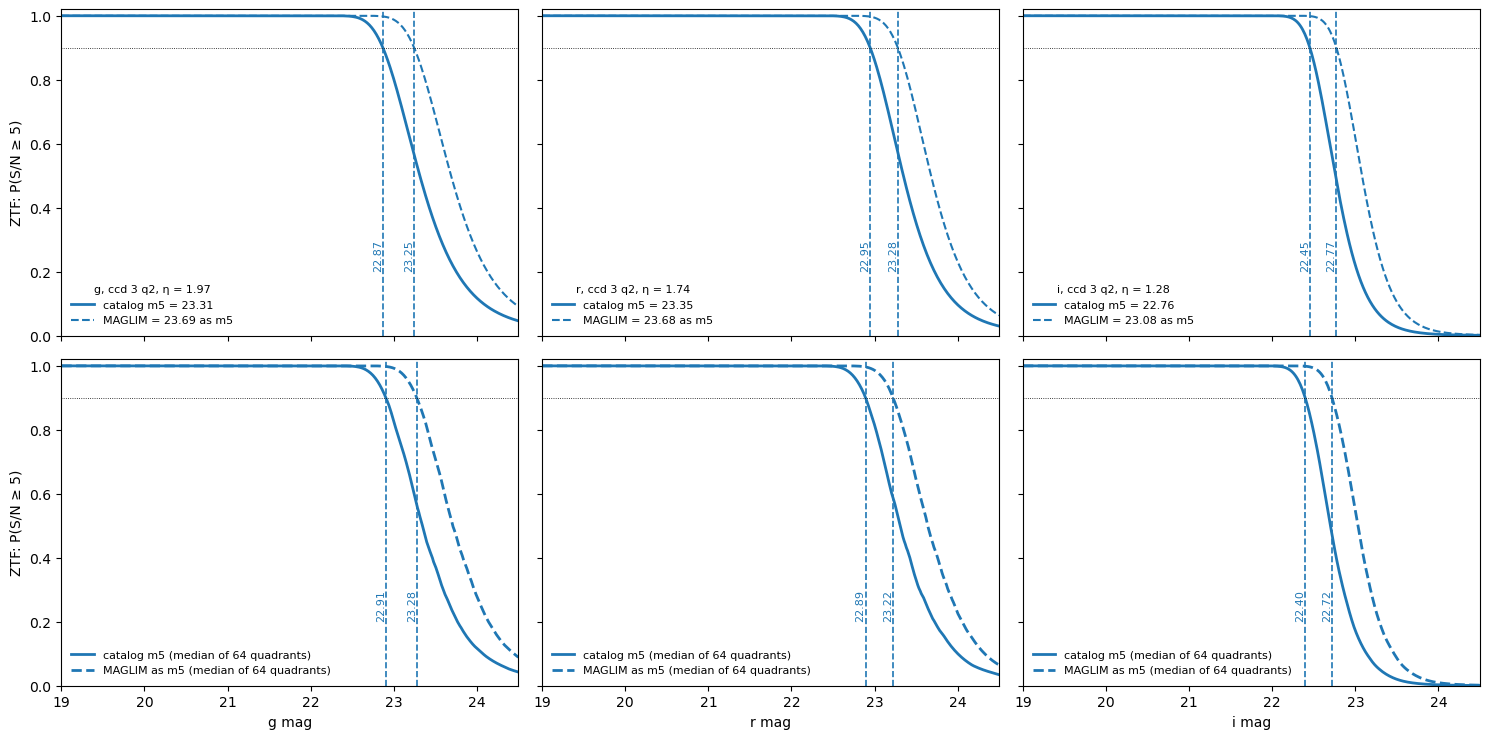

In [ ]:
zq['m90_maglim'] = m90(zq.maglim, zq.eta)
display(zq.groupby('band')[['m5', 'maglim', 'm90', 'm90_maglim']].median().round(2).loc[list('gri')].rename(columns={'m90': 'm90 (catalog m5)', 'm90_maglim': 'm90 (MAGLIM as m5)'}))
fig, axes = plt.subplots(2, 3, figsize=(15, 7.5), sharex=True, sharey=True)
for ax, b in zip(axes[0], 'gri'):                                   # one quadrant
    q = zq[(zq.band == b) & (zq.ccd == QUAD[0]) & (zq.qid == QUAD[1])].iloc[0]
    ax.plot(MGRID, p_detect(MGRID, q.m5, q.eta), color='C0', lw=2, label=f'catalog m5 = {q.m5:.2f}')
    ax.plot(MGRID, p_detect(MGRID, q.maglim, q.eta), color='C0', lw=1.5, ls='--', label=f'MAGLIM = {q.maglim:.2f} as m5')
    vline(ax, q.m90, 'C0', 0.3); vline(ax, q.m90_maglim, 'C0', 0.3, ls='--')
    ax.axhline(0.9, color='k', lw=0.6, ls=':'); ax.set_ylim(0, 1.02); ax.set_xlim(MGRID[0], MGRID[-1])
    ax.legend(frameon=False, fontsize=8, loc='lower left', title=f'{b}, ccd {QUAD[0]} q{QUAD[1]}, η = {q.eta:.2f}', title_fontsize=8)
for ax, b in zip(axes[1], 'gri'):                                   # field median of the quadrant curves
    s = zq[zq.band == b]
    for col, ls, label in (('m5', '-', 'catalog m5'), ('maglim', '--', 'MAGLIM as m5')):
        ax.plot(MGRID, np.median([p_detect(MGRID, r[col], r.eta) for _, r in s.iterrows()], axis=0), color='C0', lw=2, ls=ls, label=f'{label} (median of {len(s)} quadrants)')
    vline(ax, s.m90.median(), 'C0', 0.3); vline(ax, s.m90_maglim.median(), 'C0', 0.3, ls='--')
    ax.axhline(0.9, color='k', lw=0.6, ls=':'); ax.set_xlabel(f'{b} mag'); ax.legend(frameon=False, fontsize=8, loc='lower left')
axes[0, 0].set_ylabel('ZTF: P(S/N ≥ 5)'); axes[1, 0].set_ylabel('ZTF: P(S/N ≥ 5)')
plt.tight_layout(); plt.show()

## The two surveys side by side

The field-median recovery curve of each survey per band: PS1 from the published injections, ZTF from the model.

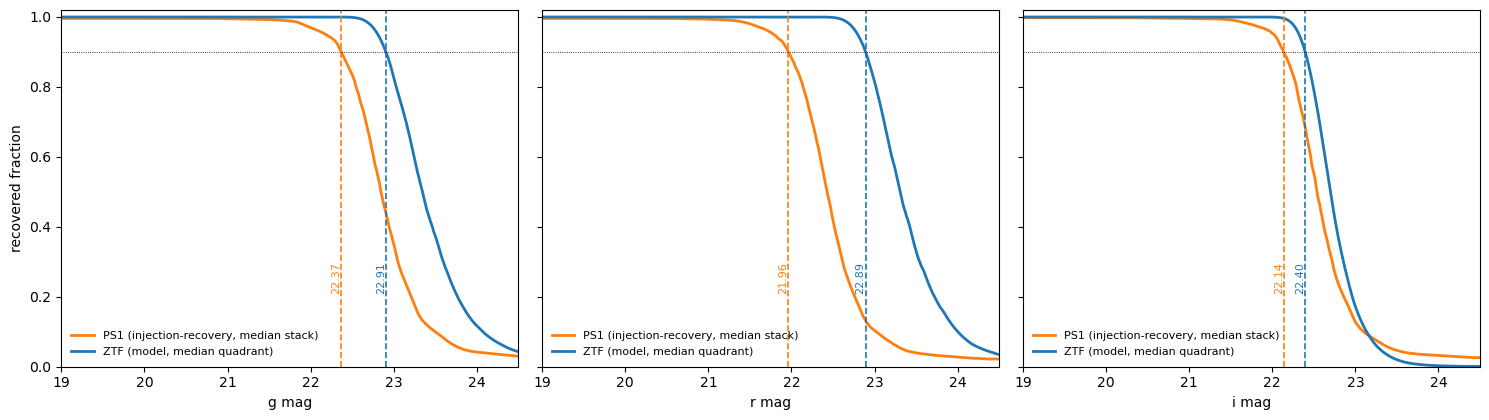

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3), sharey=True)
for ax, b in zip(axes, 'gri'):
    ax.plot(MGRID, ps1_median[b], color='C1', lw=2, label='PS1 (injection-recovery, median stack)')
    ax.plot(MGRID, ztf_median[b], color='C0', lw=2, label='ZTF (model, median quadrant)')
    vline(ax, st.loc[st.band == b, 'm90'].median(), 'C1', 0.3); vline(ax, zq.loc[zq.band == b, 'm90'].median(), 'C0', 0.3)
    ax.axhline(0.9, color='k', lw=0.6, ls=':'); ax.set_xlim(MGRID[0], MGRID[-1]); ax.set_ylim(0, 1.02)
    ax.set_xlabel(f'{b} mag'); ax.legend(frameon=False, fontsize=8, loc='lower left')
axes[0].set_ylabel('recovered fraction')
plt.tight_layout(); plt.show()

## What a source at the 75 % and 50 % recovery magnitudes looks like

The pipeline reads each survey's limit at 90 % recovery. Before moving it, look at the objects: for each survey and level, field-860
objects that survey detects within ±0.15 mag of the level's magnitude (the field median over stacks / quadrants) in band `BAND`, as
ZTF reference | PS1 stack pairs, 30″ (the PS1 stamps binned 4×4 to ZTF-like 1″ pixels for display: at 0.25″/px a 6σ source has a 1σ peak pixel) (white ○ ZTF objects, orange □ PS1 objects, red + the object). Where the other survey's
stamp still shows nothing for a source at that magnitude, a non-detection there is informative and the limit can sit at that level;
where it starts showing faint sources the catalog missed, the level is too deep.

In [ ]:
from experiments.common import Stamps, stamp_figure
BAND, N_SHOW, HALF = 'r', 8, 0.15
levels = {}
for p in (0.75, 0.5):
    levels[('PS1', p)] = {b: float(np.nanmedian(recovery_mag(st[st.band == b], p))) for b in 'gri'}
    levels[('ZTF', p)] = {b: float(np.nanmedian(zq.loc[zq.band == b, 'm5'] - 2.5 * np.log10(1 + norm.ppf(p) * zq.loc[zq.band == b, 'eta'] / T))) for b in 'gri'}
display(pd.DataFrame({f'{s} {int(100 * p)}%': v for (s, p), v in levels.items()}).round(2))
cols = ['ra', 'dec', 'ztf_idx', 'ps1_idx', 'ps1_ra', 'ps1_dec', 'catalog', 'nearest_other_arcsec', 'bright_star_d_over_R', 'in_star_spike'] + [f'{b}_{c}' for b in 'gri' for c in ('ccd', 'qid', 'ztf_psf', 'ps1_psf', 'ztf_status', 'ps1_status', 'ztf_snr', 'ps1_snr', 'ztf_nan_dist', 'ztf_covered')]
src = pd.read_parquet(f'{D}/fields/{FIELD:06d}/filter/objects.parquet', columns=cols)
# clean: both sides usable in every band (no X), outside the bright-star masks, > 20 px from any masked ZTF pixel, no other object within 5"
clean = np.all([(src[f'{b}_ztf_status'] != 'X') & (src[f'{b}_ps1_status'] != 'X') & (src[f'{b}_ztf_nan_dist'] > 20) for b in 'gri'], axis=0) \
        & ~((src.bright_star_d_over_R < 1) | src.in_star_spike) & ~(src.nearest_other_arcsec <= 5)
print(f'clean objects: {clean.sum():,} of {len(src):,}')
stamps = Stamps(FIELD, src, D)
stamps.ps1_bin_px = 4                           # display the PS1 stamps binned 4x4 to ZTF-like 1" pixels: at 0.25"/px a 6-sigma source has a ~1-sigma peak pixel

,PS1 75%,ZTF 75%,PS1 50%,ZTF 50%
g,22.61,23.09,22.85,23.35
r,22.20,23.07,22.43,23.31
i,22.33,22.53,22.54,22.70


clean objects: 2,331,724 of 7,194,532


PS1 r at its 75% magnitude (22.20 ± 0.15): 50,409 objects, 78% also detected by ZTF at S/N >= 5
ZTF r at its 75% magnitude (23.07 ± 0.15): 70,695 objects, 6% also detected by PS1 at S/N >= 5
PS1 r at its 50% magnitude (22.43 ± 0.15): 45,678 objects, 73% also detected by ZTF at S/N >= 5
ZTF r at its 50% magnitude (23.31 ± 0.15): 46,289 objects, 2% also detected by PS1 at S/N >= 5


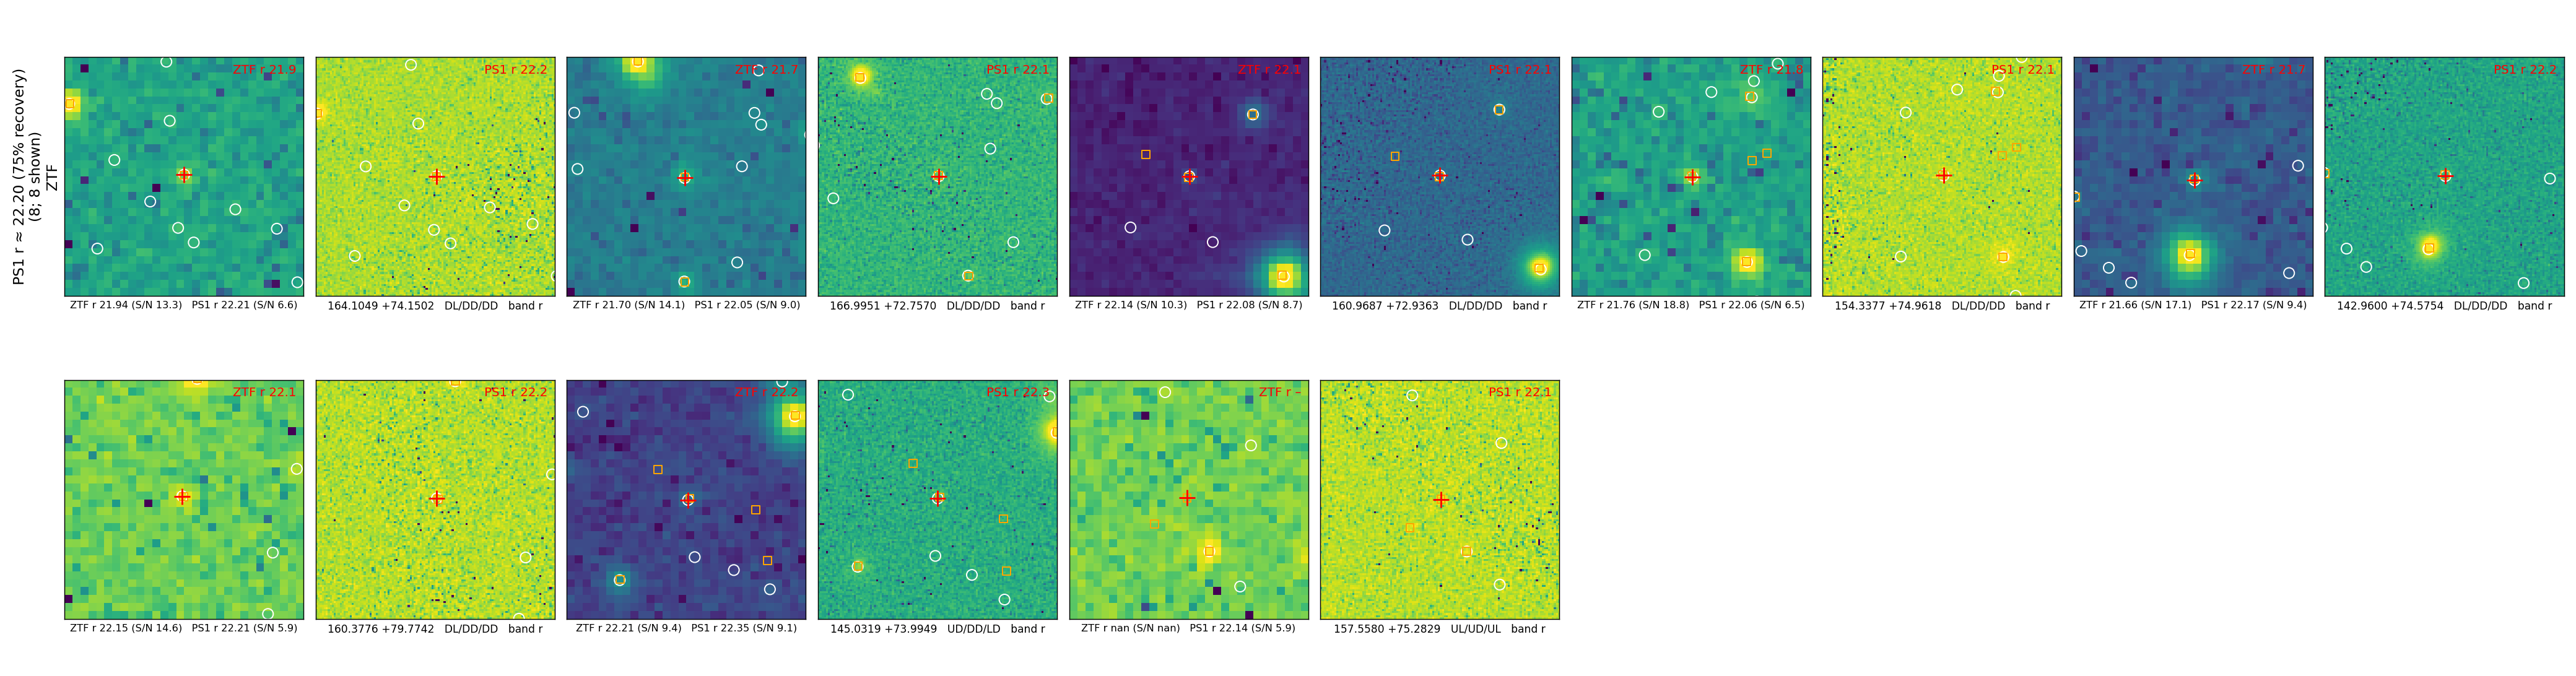

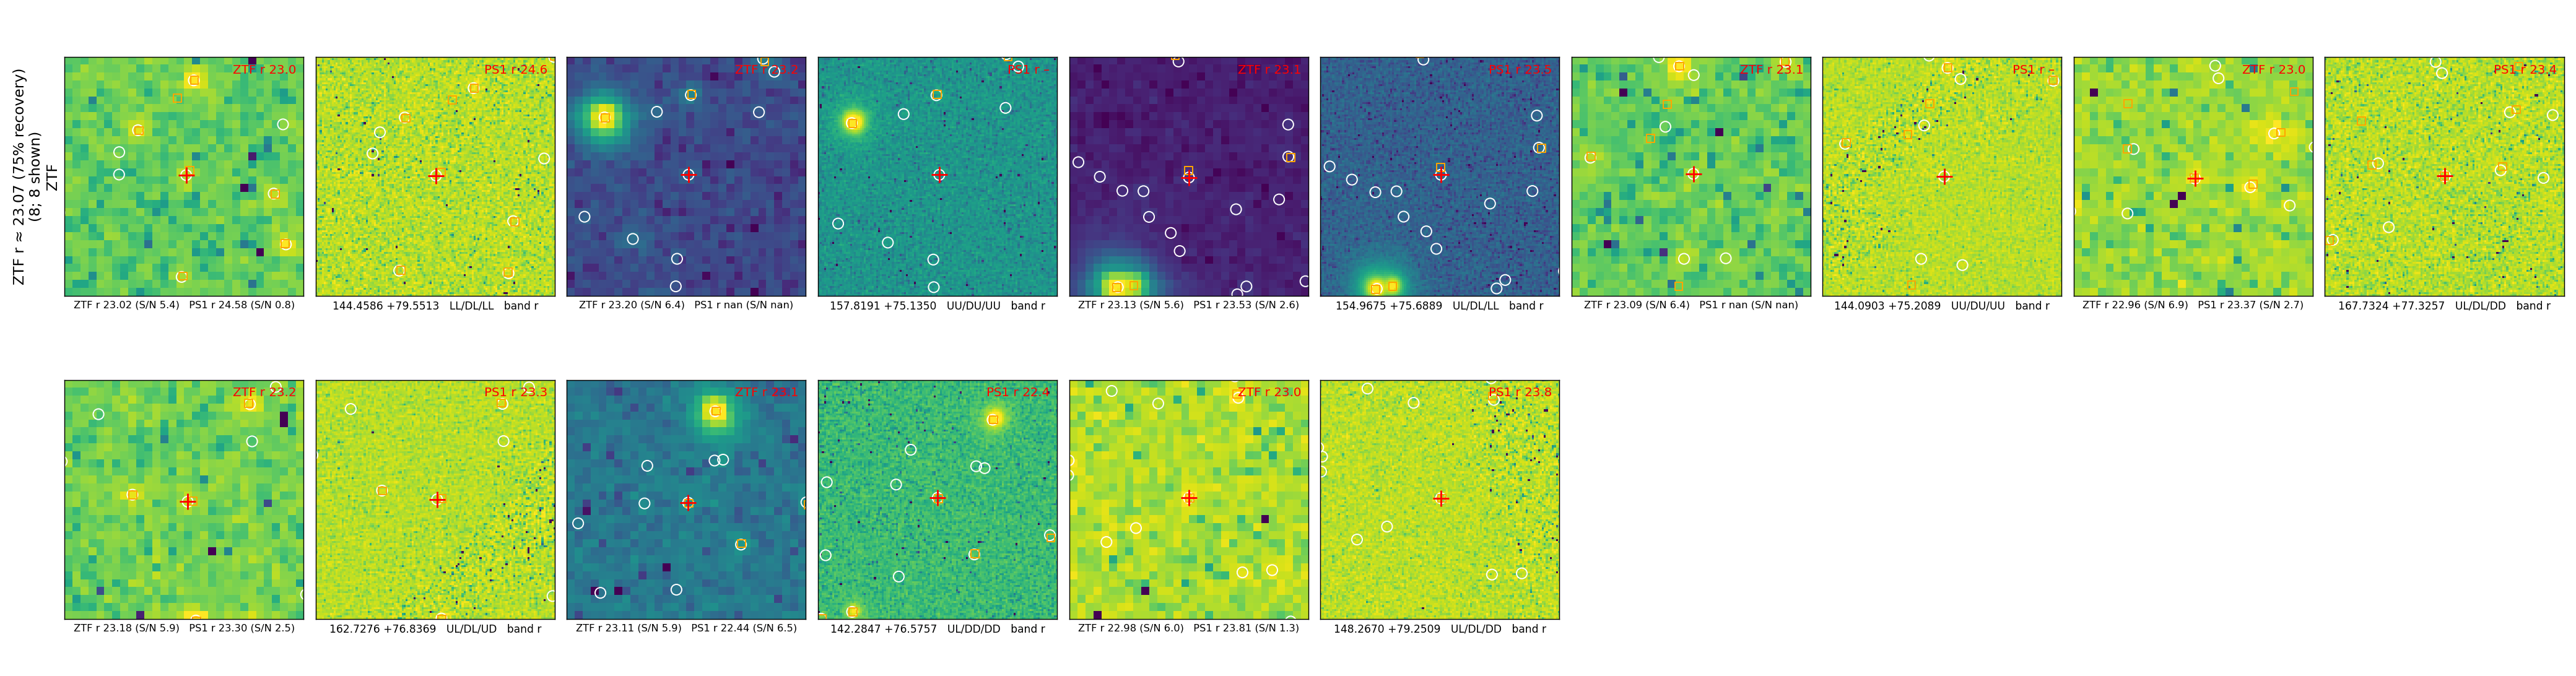

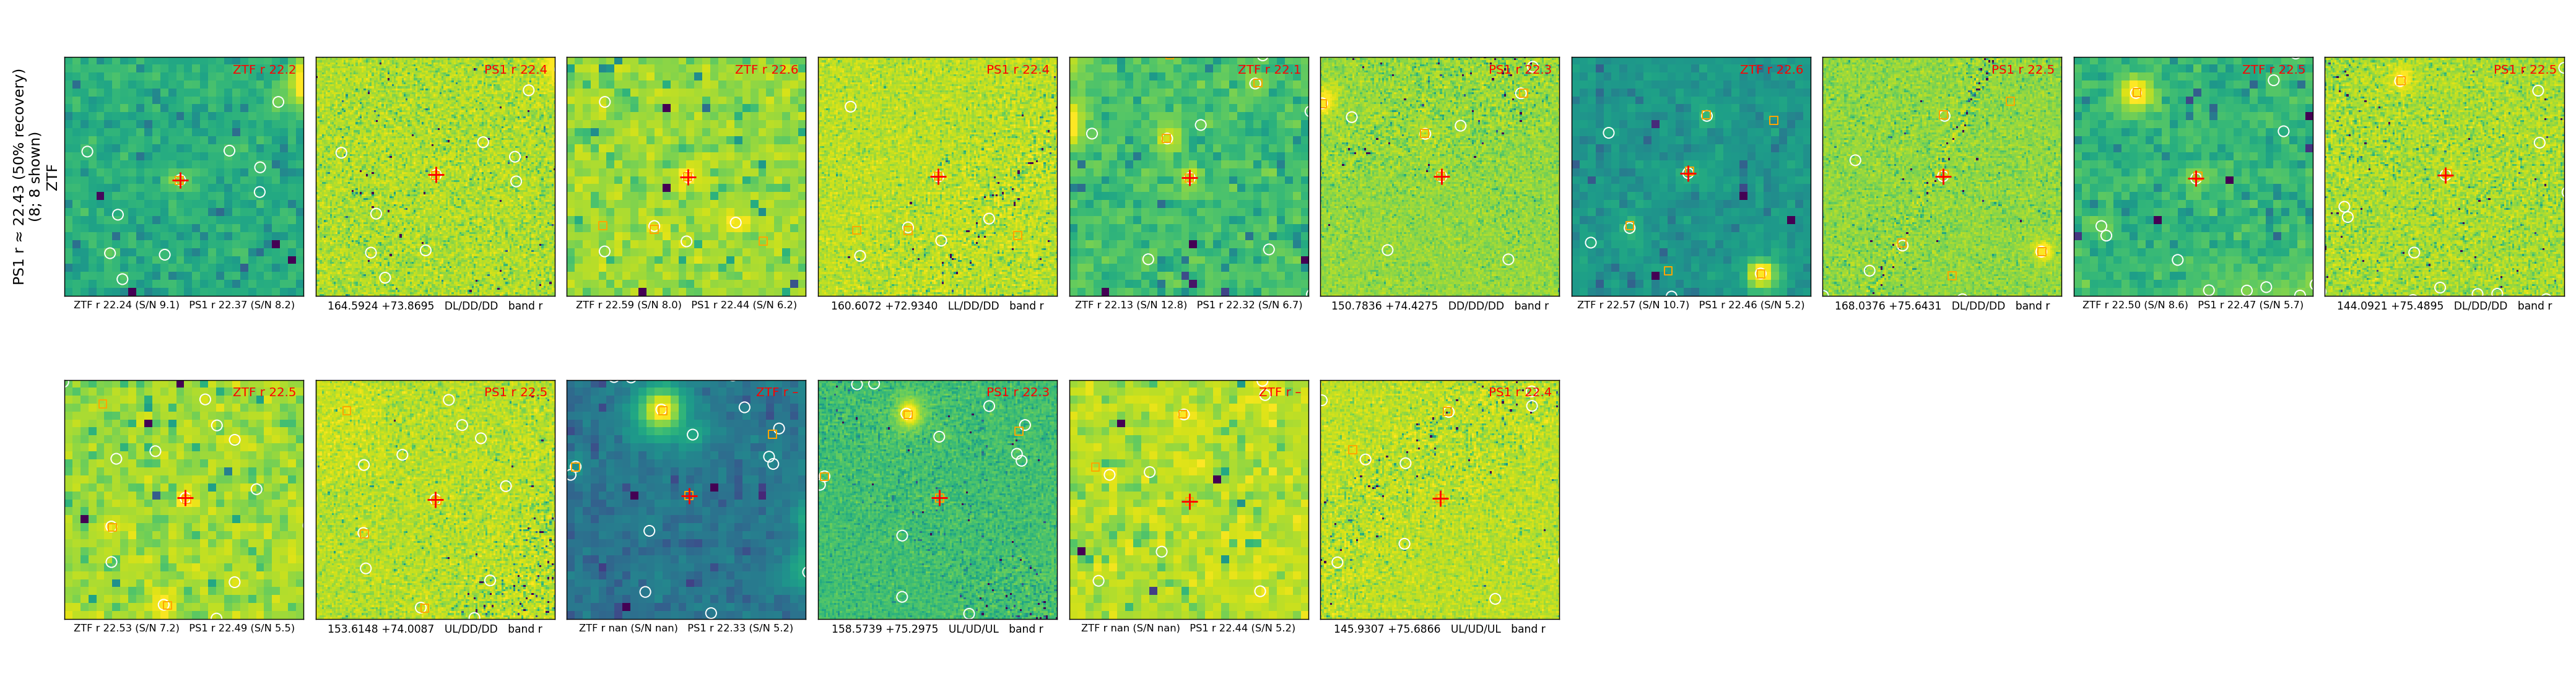

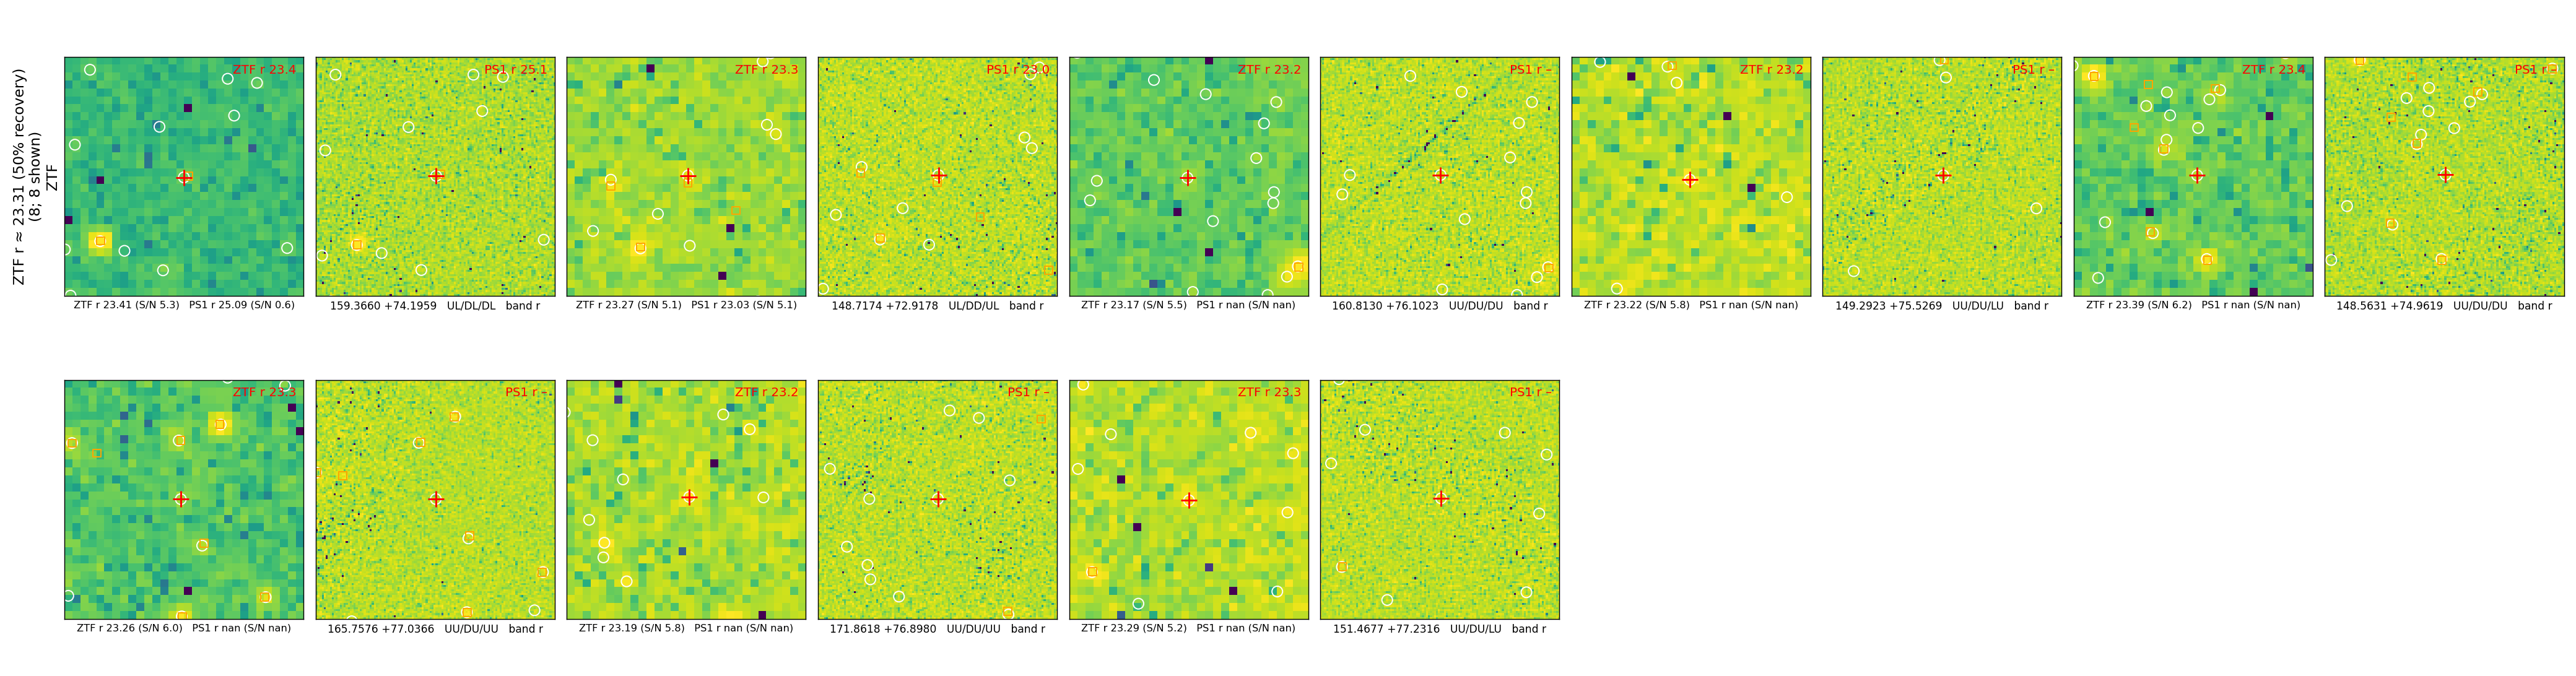

In [ ]:
rng = np.random.default_rng(0)
for (survey, p), lim in levels.items():
    m = lim[BAND]
    mag = src[f'{BAND}_ztf_psf'].values if survey == 'ZTF' else src[f'{BAND}_ps1_psf'].values
    snr = src[f'{BAND}_ztf_snr'].values if survey == 'ZTF' else src[f'{BAND}_ps1_snr'].values
    rows = np.flatnonzero((np.abs(mag - m) < HALF) & (snr >= 5) & clean)
    pick = rng.choice(rows, min(N_SHOW, len(rows)), replace=False)
    other = 'PS1' if survey == 'ZTF' else 'ZTF'
    seen = (src[f'{BAND}_ps1_snr' if survey == 'ZTF' else f'{BAND}_ztf_snr'].values[rows] >= 5).mean()
    print(f'{survey} {BAND} at its {int(100 * p)}% magnitude ({m:.2f} ± {HALF}): {len(rows):,} objects, {100 * seen:.0f}% also detected by {other} at S/N >= 5')
    stamp_figure(stamps, src, pick, f'{D}/fields/{FIELD:06d}/review/experiments/recovery_stamps_{survey}_{int(100 * p)}_{BAND}.png',
                 f'{survey} {BAND} ≈ {m:.2f} ({int(100 * p)}% recovery)', n=N_SHOW, band_of={int(i): BAND for i in pick},
                 captions=lambda i: f"ZTF {BAND} {src[f'{BAND}_ztf_psf'].values[i]:.2f} (S/N {src[f'{BAND}_ztf_snr'].values[i]:.1f})   PS1 {BAND} {src[f'{BAND}_ps1_psf'].values[i]:.2f} (S/N {src[f'{BAND}_ps1_snr'].values[i]:.1f})")
from IPython.display import Image
for (survey, p) in levels:
    display(Image(f'{D}/fields/{FIELD:06d}/review/experiments/recovery_stamps_{survey}_{int(100 * p)}_{BAND}.png', width=1600))

## Open

- PS1: adopt the injection m90 per stack (own skycell, else nearest), or go straight to P(D | m) as the significance of a miss?
- ZTF: check η against a flux-space measurement (scatter of ZTF about the PS1-predicted flux over the catalog error), and the model against the
  cross-match recovery per quadrant. What plateau ε do the clean references give?
- Extended objects: PS1's fakes and the ZTF model are both point sources.